<a href="https://colab.research.google.com/github/davichomendez1901-byte/Simulaci-n-Remix/blob/main/RandomWalk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Consideremos una secuencia de 0s y 1s de longitud m.

Llamremos una buena cadena a aquella que no tenga 1´s adayacentes.

Por lo que entonces $m$ será la longitud de mi cadena y $2^m$ serán todas las posibles combinaciones de 0´s y 1´s que podre obtener con dicha logitud $m$.


Para el caso general de una cadena de longitud $m$, sea $G$ el conjunto
de buenas cadenas y $K$ el número total de buenas cadenas.

Si $r(x)$ representa el número de 1's presentes en una cadena $x$,
entonces el valor esperado es:

$$
\mu = \sum_{x\in G} r(x)\frac{1}{K}
    = \frac{1}{K}\sum_{x\in G}r(x)
$$

Sin embargo, para valores grandes de $m$, obtener todas las buenas cadenas
puede ser computacionalmente costoso. Por ello se utilizará una caminata
aleatoria sobre un grafo para estimar este valor esperado.


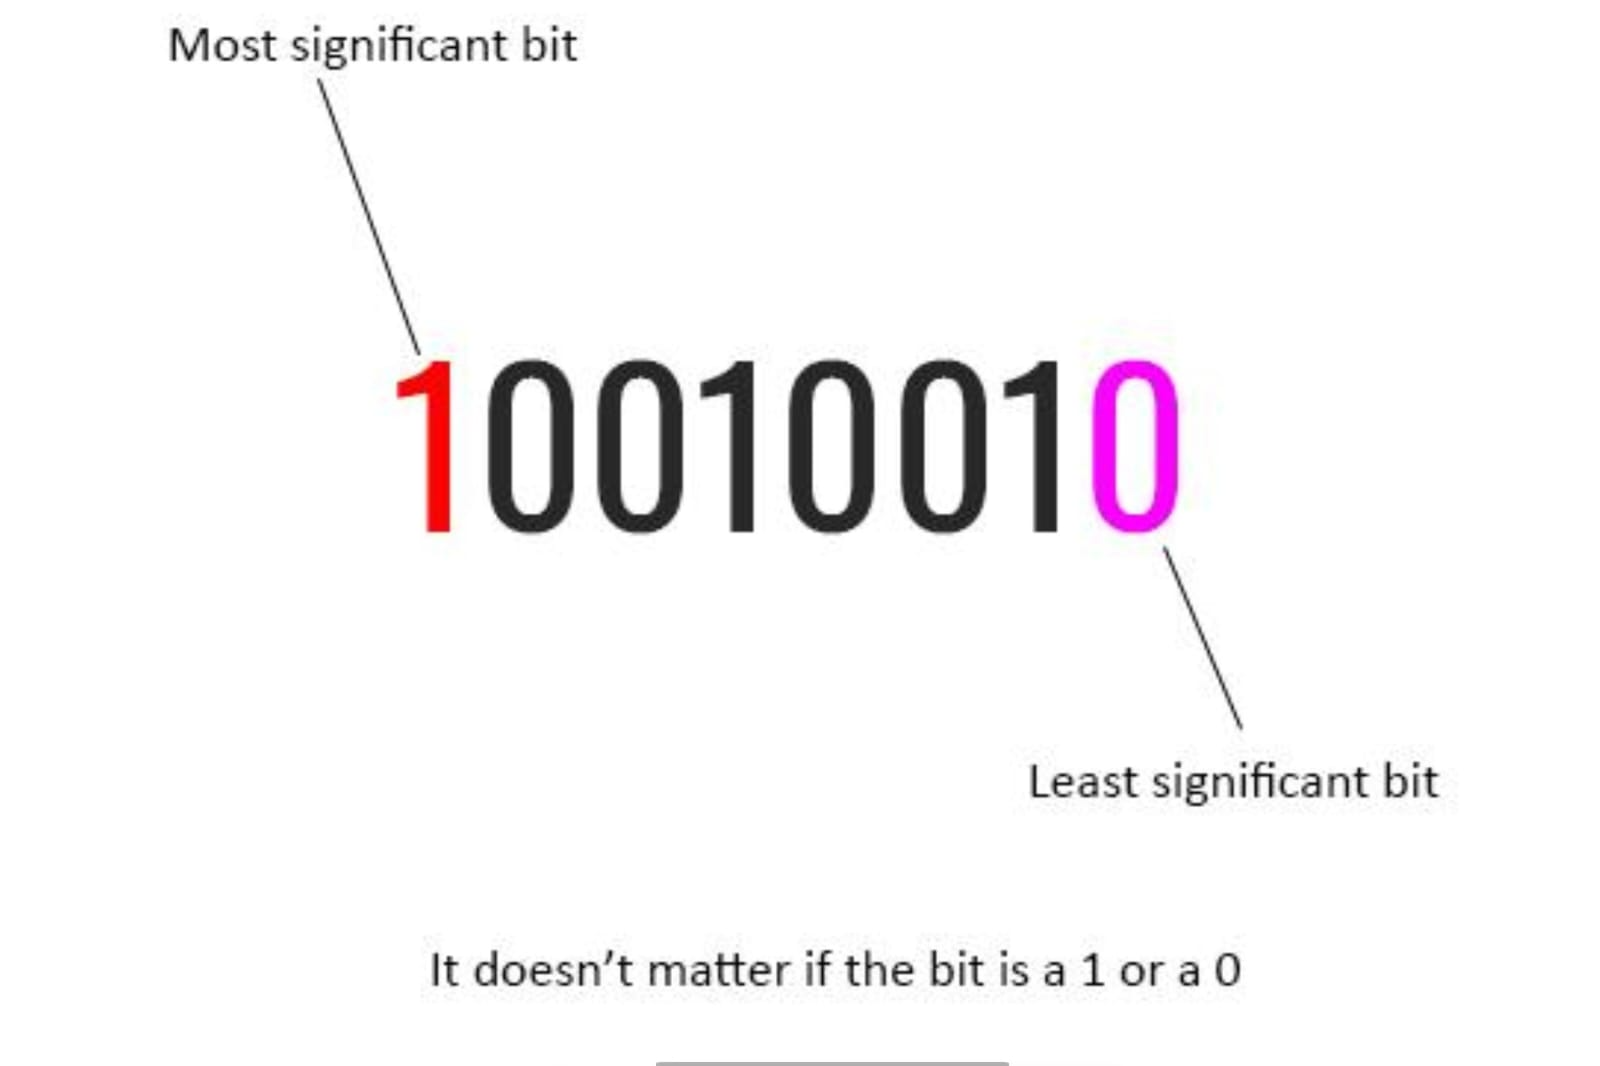

In [1]:
import numpy as np

# Longitud de la cadena
m = 4

# Estado inicial: comenzamos con una buena cadena
X = np.array([1, 0, 0, 1])

# Elegimos aleatoriamente una de las m posiciones
i = np.random.choice(m)

# Creamos una copia para no modificar directamente la cadena actual
Y = X.copy()

# Cambiamos la componente seleccionada: 0 -> 1 o 1 -> 0
Y[i] = 1 - Y[i]

# Verificamos si la nueva cadena tiene 1's adyacentes
buena = True

for j in range(m - 1):
    if Y[j] == 1 and Y[j + 1] == 1:
        buena = False
        break

# Si la propuesta es buena, nos movemos al nuevo estado.
# Si no es buena, permanecemos en el estado actual.
if buena:
    X = Y
    print("Movimiento aceptado")
else:
    print("Movimiento rechazado")

print("Posición seleccionada:", i)
print("Estado actual:", X)

Movimiento aceptado
Posición seleccionada: 3
Estado actual: [1 0 0 0]


## Simulación de la caminata aleatoria

Una vez definido cómo se realiza un movimiento, repetimos el procedimiento
un número grande de veces para generar una **caminata aleatoria** sobre el
conjunto de buenas cadenas.



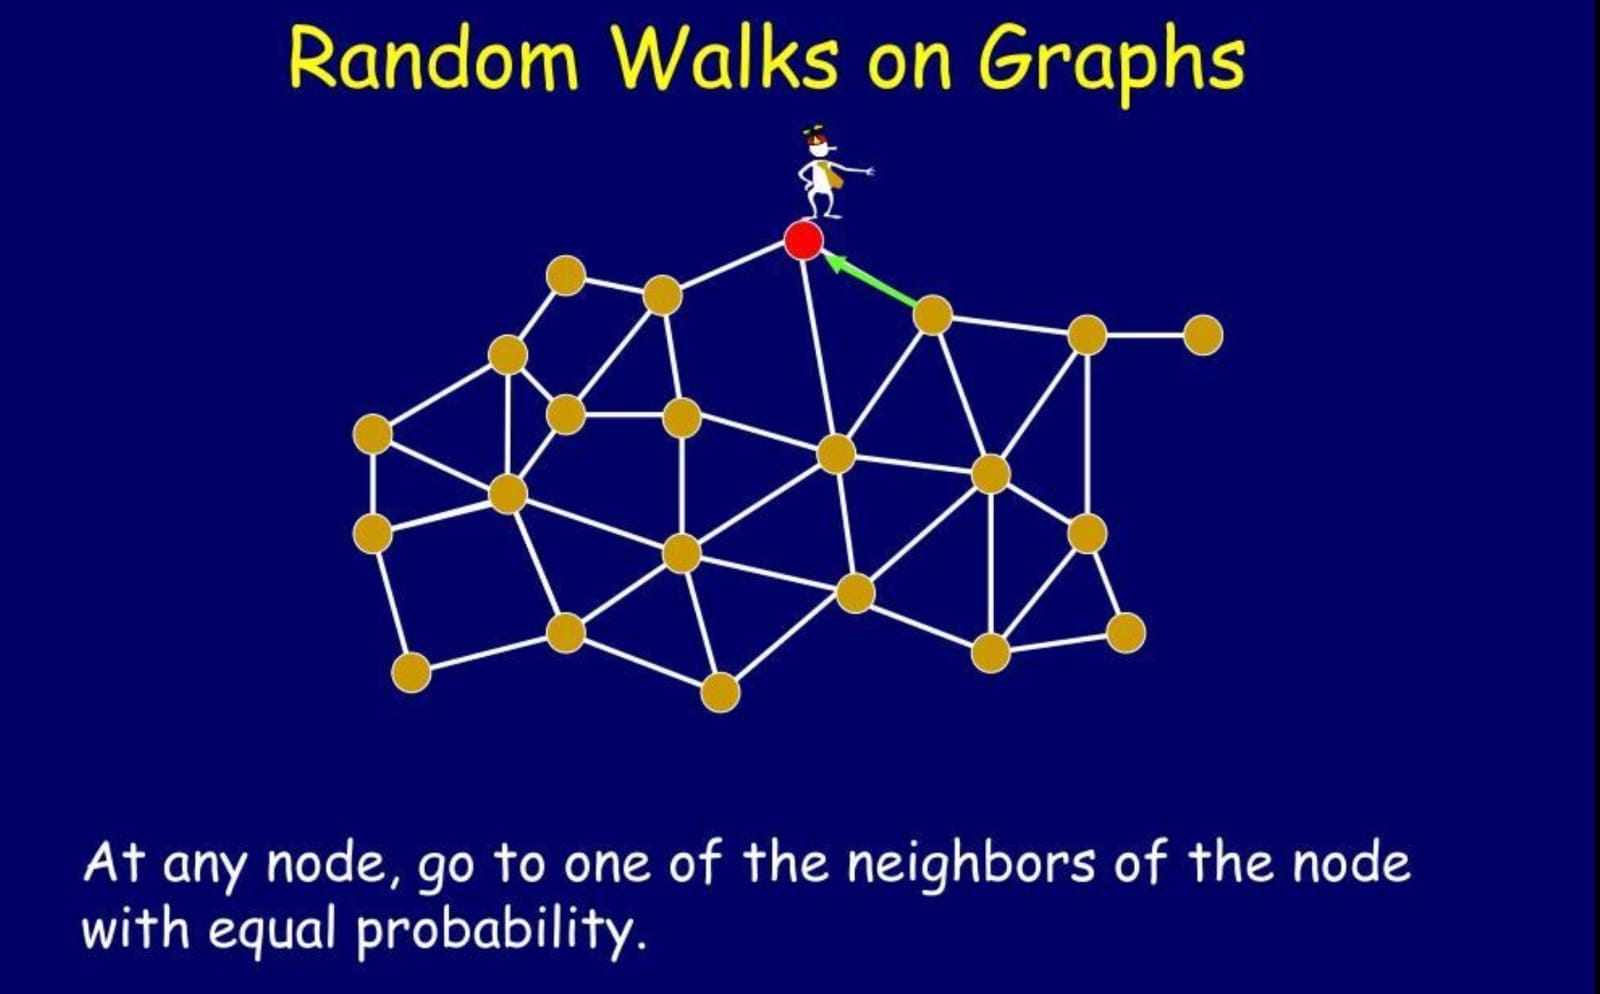



En cada iteración:

1. Se selecciona aleatoriamente una de las $m$ posiciones.
2. Se propone cambiar su valor de $0\rightarrow1$ o de $1\rightarrow0$.
3. Si la nueva cadena no contiene $1$'s adyacentes, el movimiento se acepta.
4. Si la propuesta genera dos $1$'s adyacentes, se rechaza y la cadena
   permanece en el estado actual.
5. Se registra el número de $1$'s presentes en el estado obtenido.

De esta manera obtenemos una trayectoria

$$
X_0,X_1,X_2,\ldots,X_N,
$$

sin necesidad de generar todas las posibles cadenas de longitud $m$.

Para la simulación utilizaremos $N=10000$ pasos.

In [2]:
# Número de pasos de la caminata
N = 10000

# Guardaremos el número de 1's observado en cada paso
numero_unos = []

for t in range(N):

    # Elegimos una de las m posiciones al azar
    i = np.random.choice(m)

    # Proponemos cambiar la componente seleccionada
    Y = X.copy()
    Y[i] = 1 - Y[i]

    # Verificamos si la propuesta sigue siendo una buena cadena
    buena = True

    for j in range(m - 1):
        if Y[j] == 1 and Y[j + 1] == 1:
            buena = False
            break

    # Si es buena, aceptamos el movimiento
    if buena:
        X = Y

    # Contamos el número de 1's del estado actual
    numero_unos.append(np.sum(X))

print("Estado final:", X)
print("Número de pasos:", N)

Estado final: [0 1 0 0]
Número de pasos: 10000


## Estimación del número esperado de 1's

Después de realizar la caminata aleatoria, en cada iteración se registró
el número de $1$'s presentes en la cadena.

Si $R(X_t)$ representa el número de $1$'s en el estado $X_t$, el valor
esperado puede estimarse mediante el promedio de las observaciones:

$$
\hat{\mu}=\frac{1}{N}\sum_{t=1}^{N}R(X_t).
$$

Cuando $N$ es suficientemente grande, este promedio proporciona una
aproximación del número esperado de $1$'s en una buena cadena.

In [3]:
# Estimamos el número esperado de 1's
media_unos = np.mean(numero_unos)

print("Número esperado estimado de 1's:", media_unos)

Número esperado estimado de 1's: 1.2474


## Comprobación del resultado para $m=4$

Para verificar el funcionamiento de la simulación, consideramos el caso
$m=4$, donde es posible enumerar directamente todas las buenas cadenas.

Las buenas cadenas son:

$$
0000,\;0001,\;0010,\;0100,\;0101,\;1000,\;1001,\;1010.
$$

El número de $1$'s en cada una es:

$$
0,\;1,\;1,\;1,\;2,\;1,\;2,\;2.
$$

Como todas las buenas cadenas tienen la misma probabilidad, el valor
esperado exacto es:

$$
E[R(X)]
=
\frac{0+1+1+1+2+1+2+2}{8}
=
\frac{10}{8}
=
1.25.
$$

Por lo tanto, el resultado obtenido mediante la caminata aleatoria debe
aproximarse a $1.25$ conforme aumenta el número de iteraciones.

In [4]:
# Valor exacto para m = 4
valor_exacto = 1.25

# Diferencia entre la simulación y el valor exacto
error = abs(media_unos - valor_exacto)

print("Valor estimado:", media_unos)
print("Valor exacto:   ", valor_exacto)
print("Error absoluto: ", error)

Valor estimado: 1.2474
Valor exacto:    1.25
Error absoluto:  0.0025999999999999357


## Convergencia de la estimación

Para observar el comportamiento de la simulación, se calcula el promedio
acumulado del número de $1$'s conforme aumenta el número de iteraciones.

El promedio acumulado en el paso $n$ está dado por:

$$
\hat{\mu}_n=\frac{1}{n}\sum_{t=1}^{n}R(X_t).
$$

Si la caminata está funcionando adecuadamente, conforme aumenta el número
de iteraciones la estimación debe estabilizarse alrededor del valor
esperado exacto, que para $m=4$ es $1.25$.

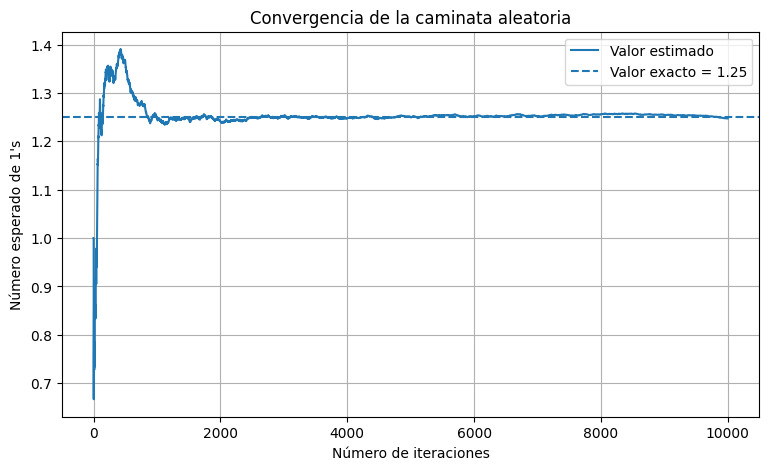

In [5]:
import matplotlib.pyplot as plt

# Calculamos el promedio acumulado
promedio_acumulado = np.cumsum(numero_unos) / np.arange(1, N + 1)

# Graficamos la convergencia
plt.figure(figsize=(9, 5))

plt.plot(promedio_acumulado, label="Valor estimado")
plt.axhline(1.25, linestyle="--", label="Valor exacto = 1.25")

plt.xlabel("Número de iteraciones")
plt.ylabel("Número esperado de 1's")
plt.title("Convergencia de la caminata aleatoria")
plt.legend()
plt.grid()

plt.show()

### Ahora

En las primeras iteraciones se observan mayores fluctuaciones debido al
pequeño número de estados recorridos. Conforme aumenta el número de pasos,
el promedio acumulado comienza a estabilizarse alrededor del valor exacto
$\mu=1.25$.

Este comportamiento muestra que la caminata aleatoria permite aproximar
el número esperado de 1's sin necesidad de enumerar todas las cadenas
posibles.

Para $m=4$, la simulación puede compararse con el resultado exacto, lo
que permite verificar el funcionamiento del método.

## Aplicación para una cadena de longitud $m=100$

Una vez comprobado el funcionamiento de la caminata aleatoria para
$m=4$, aplicamos el mismo procedimiento a una cadena de longitud
$m=100$.

En este caso existen

$$
2^{100}
$$

posibles cadenas binarias, por lo que enumerarlas y comprobar una por
una no resulta conveniente.

La caminata aleatoria permite trabajar directamente sobre buenas
cadenas y estimar el número esperado de $1$'s mediante simulación.

In [6]:
# Longitud de la cadena
m = 100

# Número de pasos de la caminata
N = 100000

# Comenzamos con una buena cadena: todos sus elementos son cero
X = np.zeros(m, dtype=int)

# Guardamos el número de 1's observado
numero_unos = []

for t in range(N):

    # Elegimos una posición uniformemente al azar
    i = np.random.choice(m)

    # Proponemos cambiar 0 <-> 1
    Y = X.copy()
    Y[i] = 1 - Y[i]

    # Comprobamos si la propuesta es una buena cadena
    buena = True

    for j in range(m - 1):
        if Y[j] == 1 and Y[j + 1] == 1:
            buena = False
            break

    # Si es buena, aceptamos el movimiento
    if buena:
        X = Y

    # Registramos el número de 1's
    numero_unos.append(np.sum(X))

# Estimación del valor esperado
media_unos = np.mean(numero_unos)

print("Longitud de la cadena:", m)
print("Número de iteraciones:", N)
print("Número esperado estimado de 1's:", media_unos)

Longitud de la cadena: 100
Número de iteraciones: 100000
Número esperado estimado de 1's: 27.81569


### Resultado para $m=100$

Después de realizar $100\,000$ iteraciones de la caminata aleatoria se obtuvo:

$$
\boxed{\hat{\mu}=27.81569}
$$

Por lo tanto, se estima que una buena cadena de longitud $100$ contiene,
en promedio, aproximadamente **27.82 unos**.

La estimación se obtuvo recorriendo únicamente estados correspondientes
a buenas cadenas, sin necesidad de generar las $2^{100}$ cadenas binarias
posibles.

## Convergencia para $m=100$

Para analizar la estabilidad de la estimación, se calcula nuevamente el
promedio acumulado del número de $1$'s durante la caminata.

Conforme aumenta el número de iteraciones, se espera que el promedio
acumulado presente menores fluctuaciones y se estabilice alrededor del
valor estimado.

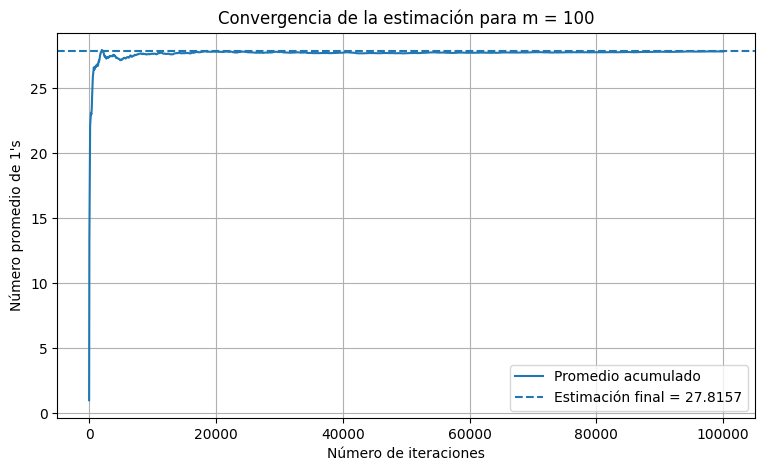

In [7]:
# Promedio acumulado
promedio_acumulado = np.cumsum(numero_unos) / np.arange(1, N + 1)

plt.figure(figsize=(9, 5))

plt.plot(promedio_acumulado, label="Promedio acumulado")

# Línea correspondiente a la estimación final
plt.axhline(media_unos, linestyle="--",
            label=f"Estimación final = {media_unos:.4f}")

plt.xlabel("Número de iteraciones")
plt.ylabel("Número promedio de 1's")
plt.title("Convergencia de la estimación para m = 100")

plt.legend()
plt.grid()
plt.show()

## Conclusión

Mediante una caminata aleatoria sobre el grafo de buenas cadenas se estimó
el número esperado de $1$'s sin necesidad de enumerar todas las posibles
secuencias binarias.

Primero se utilizó el caso $m=4$ para comprobar el funcionamiento del
método, obteniendo una estimación cercana al valor exacto de $1.25$.

Posteriormente, para una cadena de longitud $m=100$ y $100\,000$
iteraciones, se obtuvo:

$$
\boxed{\hat{\mu}\approx27.8157}
$$

Por lo tanto, se estima que una buena cadena de longitud $100$ contiene
aproximadamente **27.82 unos en promedio**.

La gráfica de convergencia muestra que, aunque existen fluctuaciones
durante las primeras iteraciones, el promedio acumulado se estabiliza
conforme aumenta el número de pasos de la caminata.